# 03 — Bốn nguồn dữ liệu thật  ·  Bước 3: Hiểu dữ liệu

**Vì sao có notebook này.** Từ đầu tới giờ, các "bệnh viện" của ta là giả: ta lấy tập train rồi chia
nhãn theo phân phối Dirichlet. Cách đó chỉ tạo ra một kiểu khác biệt, đó là *bệnh viện này nhiều ca
ác tính, bệnh viện kia toàn nốt ruồi*. Nhưng hai bệnh viện thật còn khác nhau ở **cái máy chụp**: màu
da trên ảnh, độ sáng, viền đen của ống soi. Dirichlet không mô phỏng được kiểu khác biệt này.

HAM10000 thật ra được gom từ nhiều nơi: Khoa Da liễu Đại học Y Vienna và một phòng khám ở Queensland,
Úc (Tschandl và c.s., 2018). File metadata gốc có cột `dataset` ghi nguồn của từng ảnh. Benchmark FLamby
(Fed-ISIC2019) đã dùng chính cột này để chia HAM10000 thành 4 trung tâm.

Notebook trả lời năm câu hỏi:

1. Mỗi ảnh thuộc nguồn nào? File metadata có khớp với dữ liệu ta đang dùng không?
2. Bốn nguồn lệch nhau **về nhãn** tới đâu, đặt lên cùng thang đo với các kịch bản Dirichlet?
3. Nhãn ở các nguồn có **đáng tin như nhau** không?
4. Ảnh của các nguồn **trông có khác nhau** không: màu, viền đen?
5. Chỉ nhìn màu ảnh, có **đoán được ảnh từ nguồn nào** không, kể cả khi chỉ xét cùng một loại bệnh?

**Đọc kết quả thế nào (viết trước khi chạy):**

- Câu 2: JS trung bình của 4 nguồn thật nằm gần kịch bản Dirichlet nào thì độ lệch nhãn tự nhiên tương
  đương kịch bản đó.
- Câu 5: có 4 nguồn nên đoán bừa được balanced accuracy ≈ 0,25. Nếu **chỉ xét ảnh NV** mà vẫn đoán nguồn
  được rõ hơn mức bừa (ví dụ > 0,5), thì khác biệt về ảnh giữa các nguồn là thật. Khi đó chuẩn hoá màu
  (bước 5) và FedBN (bước 8) có lý do để thử. Nếu ≈ 0,25 thì hai hướng đó ít triển vọng.

Đầu ra: `ketqua/nguon.csv`, mỗi ảnh train/val một dòng kèm nguồn của nó. Bước 6 dùng file này để chia
máy trạm theo nguồn thật.

In [1]:
import hashlib, urllib.request
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from PIL import Image
from scipy.spatial.distance import jensenshannon
from du_lieu import GOC, RA, LOP, nap_dem

NGUON = ["vidir_molemax", "vidir_modern", "rosendahl", "vienna_dias"]
cs = pd.read_csv(RA / "chia_tap.csv")
tv = cs[cs.phan.isin(["train", "val"])].copy()          # 10.015 ảnh của HAM10000
print(tv.phan.value_counts().to_string())

phan
train    8583
val      1432


## 1. Lấy metadata có cột nguồn

Bộ ISIC 2018 ta tải về không có cột nguồn. Cột này nằm trong `HAM10000_metadata` trên Harvard
Dataverse. Repo FLamby giữ một bản sao của đúng file đó. Ô dưới tải bản sao này một lần, rồi kiểm mã
SHA-256 để chắc file không bị đổi so với bản tớ đã kiểm tra.

In [2]:
URL = "https://raw.githubusercontent.com/owkin/FLamby/main/flamby/datasets/fed_isic2019/HAM10000_metadata"
SHA = "de17ec44cb25ea9c3f6378ba18d69224c740afd62e86ec2edc6a894d6aa663d3"
f_meta = GOC / "HAM10000_metadata.csv"
if not f_meta.exists():
    urllib.request.urlretrieve(URL, f_meta)
ma = hashlib.sha256(f_meta.read_bytes()).hexdigest()
print("SHA-256 khớp" if ma == SHA else f"CẢNH BÁO: SHA khác ({ma[:12]}...) — dừng lại báo tớ")
meta = pd.read_csv(f_meta)
print(meta.shape, list(meta.columns))
meta.dataset.value_counts()

SHA-256 khớp
(10015, 8) ['lesion_id', 'image_id', 'dx', 'dx_type', 'age', 'sex', 'localization', 'dataset']


dataset
vidir_molemax    3954
vidir_modern     3363
rosendahl        2259
vienna_dias       439
Name: count, dtype: int64

## 2. Kiểm khớp

Trước khi tin cột nguồn, phải chắc ba điều: (a) ảnh nào cũng tìm thấy trong metadata, (b) chẩn đoán
trong metadata trùng với nhãn ta đang dùng, (c) mã tổn thương trùng với file `LesionGroupings`. Lệch
dù một ảnh cũng phải biết.

In [3]:
tv = tv.merge(meta[["image_id", "lesion_id", "dx", "dx_type", "dataset"]]
              .rename(columns={"image_id": "image", "lesion_id": "lesion_meta", "dataset": "nguon"}),
              on="image", how="left")
print(f"(a) ảnh không có trong metadata: {tv.nguon.isna().sum()}")
print(f"(b) chẩn đoán lệch nhãn: {(tv.dx.str.upper() != tv.lop).sum()}")
print(f"(c) mã tổn thương lệch:  {(tv.lesion_meta != tv.lesion_id).sum()}")

# tổn thương có ảnh ở nhiều nguồn: gán cả tổn thương về nguồn chiếm nhiều ảnh nhất,
# để khi chia máy trạm theo nguồn thì một tổn thương không bị xé ra hai bệnh viện
nhieu = tv.groupby("lesion_id").nguon.nunique()
print(f"\nTổn thương có ảnh ở nhiều nguồn: {(nhieu > 1).sum()} / {len(nhieu)}")
chinh = tv.groupby("lesion_id").nguon.agg(lambda s: s.value_counts().index[0])
doi = (tv.lesion_id.map(chinh) != tv.nguon).sum()
tv["nguon"] = tv.lesion_id.map(chinh)
print(f"-> gán về nguồn chính, {doi} ảnh đổi nguồn")

(a) ảnh không có trong metadata: 0
(b) chẩn đoán lệch nhãn: 0
(c) mã tổn thương lệch:  0

Tổn thương có ảnh ở nhiều nguồn: 9 / 7470
-> gán về nguồn chính, 9 ảnh đổi nguồn


## 3. Bốn nguồn lệch nhau về nhãn tới đâu?

Dùng đúng thước đo của notebook 02: khoảng cách Jensen–Shannon (JS) giữa phân bố lớp của từng "bệnh
viện" và phân bố chung, tính trên phần `train`. Nhờ dùng chung thước đo, ta đặt được 4 nguồn thật lên
cùng thang với các kịch bản Dirichlet đã chạy.

In [4]:
tr = tv[tv.phan == "train"]
chung = tr.lop.value_counts(normalize=True).reindex(LOP).fillna(0).values

def js_cua(cot, du_lieu):
    b = pd.crosstab(du_lieu[cot], du_lieu.lop).reindex(columns=LOP, fill_value=0)
    return [jensenshannon(r / r.sum(), chung) for r in b.values], b.sum(axis=1).values

hang = []
for c in ["may_iid", "may_dir1.0", "may_dir0.3", "may_dir0.1"]:
    js, n = js_cua(c, tr)
    hang.append(dict(kich_ban=c[4:], so_may=len(n), anh_moi_may=" / ".join(map(str, n.astype(int))),
                     JS_tb=np.mean(js), JS_max=np.max(js)))
js, n = js_cua("nguon", tr)
hang.append(dict(kich_ban="NGUỒN THẬT", so_may=len(n), anh_moi_may=" / ".join(map(str, n.astype(int))),
                 JS_tb=np.mean(js), JS_max=np.max(js)))
bang_js = pd.DataFrame(hang).round(3)
display(bang_js)

pt = pd.crosstab(tr.nguon, tr.lop, normalize="index").reindex(index=NGUON, columns=LOP) * 100
display(pt.round(1).assign(so_anh=tr.nguon.value_counts().reindex(NGUON)))

,kich_ban,so_may,anh_moi_may,JS_tb,JS_max
0,iid,5,1732 / 1678 / 1774 / 1708 / 1691,0.027,0.033
1,dir1.0,5,2765 / 886 / 2078 / 958 / 1896,0.213,0.467
2,dir0.3,5,256 / 996 / 233 / 3068 / 4030,0.416,0.594
3,dir0.1,5,211 / 1233 / 773 / 5173 / 1193,0.534,0.757
4,NGUỒN THẬT,4,1926 / 2904 / 3388 / 365,0.214,0.286


lop,MEL,NV,BCC,AKIEC,BKL,DF,VASC,so_anh
nguon,,,,,,,,
vidir_molemax,0.4,94.3,0.1,0.0,3.2,0.7,1.3,3388
vidir_modern,20.0,54.6,6.4,0.8,14.2,1.5,2.4,2904
rosendahl,15.5,35.3,12.9,13.3,21.5,1.4,0.2,1926
vienna_dias,15.9,78.6,1.1,0.0,2.5,1.1,0.8,365


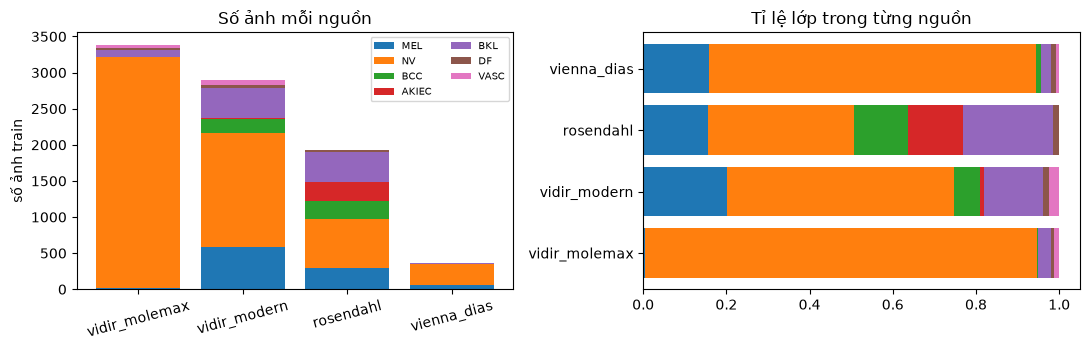

In [5]:
mau = plt.cm.tab10(np.arange(len(LOP)))
b = pd.crosstab(tr.nguon, tr.lop).reindex(index=NGUON, columns=LOP, fill_value=0)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
day = np.zeros(len(NGUON))
for j, l in enumerate(LOP):
    ax[0].bar(range(len(NGUON)), b[l].values, bottom=day, color=mau[j], label=l); day += b[l].values
    ax[1].barh(range(len(NGUON)), (b[l] / b.sum(axis=1)).values, left=(b.iloc[:, :j].sum(axis=1) / b.sum(axis=1)).values,
               color=mau[j])
ax[0].set_xticks(range(len(NGUON))); ax[0].set_xticklabels(NGUON, rotation=15); ax[0].set_ylabel("số ảnh train")
ax[0].legend(fontsize=7, ncol=2); ax[0].set_title("Số ảnh mỗi nguồn")
ax[1].set_yticks(range(len(NGUON))); ax[1].set_yticklabels(NGUON); ax[1].set_title("Tỉ lệ lớp trong từng nguồn")
plt.tight_layout(); plt.savefig(RA / "nguon_phan_bo_lop.png", dpi=110); plt.show()

## 4. Nhãn ở các nguồn có đáng tin như nhau không?

Cột `dx_type` cho biết chẩn đoán được xác nhận bằng cách nào:

- `histo`: sinh thiết mô bệnh học, chắc chắn nhất;
- `follow_up`: theo dõi nốt đó qua nhiều lần khám, thấy không đổi thì kết luận lành;
- `consensus`: các bác sĩ thống nhất trên ảnh;
- `confocal`: kính hiển vi đồng tiêu.

Nếu một nguồn chủ yếu là `follow_up` thì nhãn ở đó "mềm" hơn. Đây là một khác biệt nữa giữa các bệnh
viện mà Dirichlet không có.

In [6]:
xn = pd.crosstab(tv.nguon, tv.dx_type, normalize="index").reindex(NGUON) * 100
xn.round(1)

dx_type,confocal,consensus,follow_up,histo
nguon,,,,
vidir_molemax,0.0,5.1,93.8,1.0
vidir_modern,2.0,20.8,0.0,77.2
rosendahl,0.0,0.0,0.0,100.0
vienna_dias,0.0,0.0,0.0,100.0


## 5. Ảnh của các nguồn trông có khác nhau không?

Để so cho công bằng, **chỉ lấy ảnh NV** (nốt ruồi lành), loại có ở cả bốn nguồn. Như vậy khác biệt nhìn
thấy là do nguồn chụp chứ không phải do loại bệnh. Mỗi hàng là một nguồn.

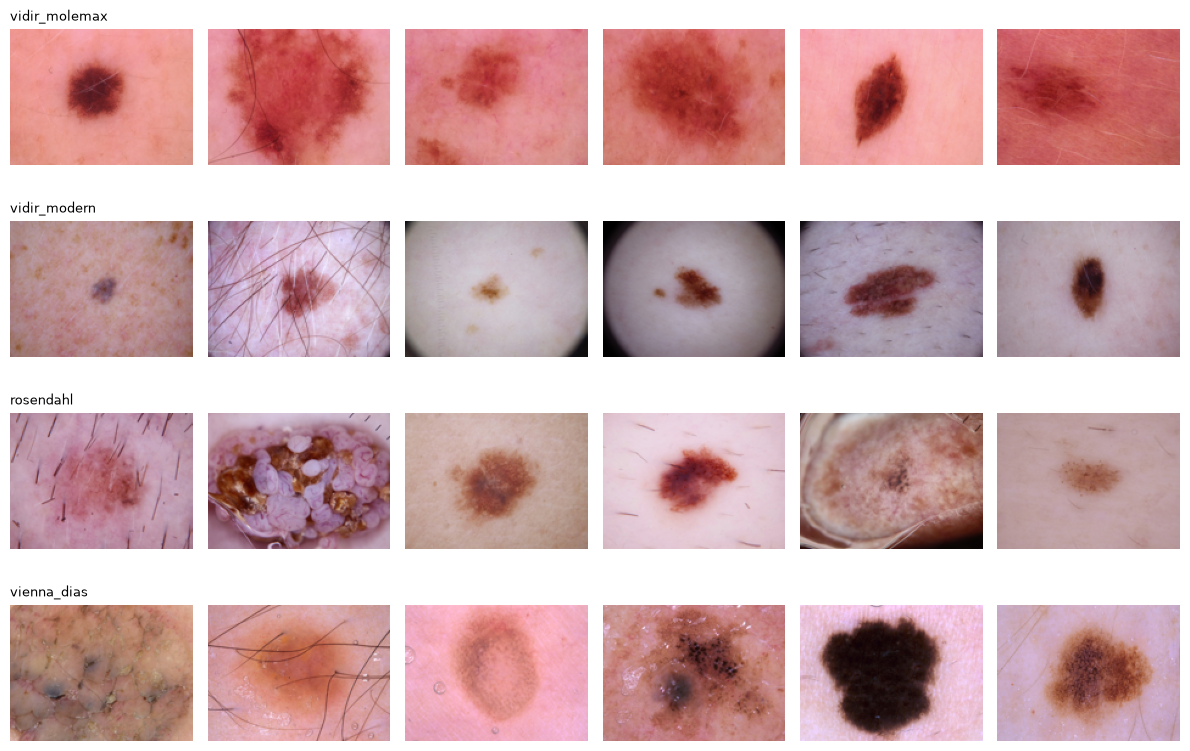

In [7]:
fig, ax = plt.subplots(len(NGUON), 6, figsize=(12, 2.0 * len(NGUON)))
for i, s in enumerate(NGUON):
    m = tv[(tv.nguon == s) & (tv.lop == "NV")].sample(6, random_state=0)
    for j in range(6):
        ax[i, j].imshow(Image.open(m.duong_dan.iloc[j]).resize((150, 112))); ax[i, j].axis("off")
    ax[i, 0].set_title(s, loc="left", fontsize=9)
plt.tight_layout(); plt.savefig(RA / "nguon_anh_mau_NV.png", dpi=110); plt.show()

Giờ đo bằng số. Mỗi ảnh lấy từ bộ đệm 224×224 đã có, tính bảy con số đơn giản:

- màu trung bình và độ tản màu (R, G, B) ở **vùng giữa** 112×112, nơi thường là da và tổn thương;
- **độ tối ở bốn góc**: ảnh chụp qua ống soi tròn thì bốn góc đen.

Ảnh bị gắn cờ "có viền đen" khi độ sáng trung bình ở góc dưới 40/255. Ngưỡng này chọn bằng mắt, chưa
chuẩn; ô sau in ra vài ảnh bị gắn cờ để cậu kiểm lại.

In [8]:
X = nap_dem(tv, 224)                                     # uint8 [N, 224, 224, 3], đúng thứ tự tv

def dac_trung(X, lo=1000):
    out = []
    for i in range(0, len(X), lo):
        x = X[i:i + lo].astype(np.float32)
        giua = x[:, 56:168, 56:168]
        goc = np.concatenate([x[:, :16, :16], x[:, :16, -16:], x[:, -16:, :16], x[:, -16:, -16:]], 1)
        out.append(np.column_stack([giua.mean((1, 2)), giua.std((1, 2)), goc.mean((1, 2, 3))]))
    return np.concatenate(out)

F = dac_trung(X)
COT = ["R_tb", "G_tb", "B_tb", "R_tan", "G_tan", "B_tan", "do_sang_goc"]
tv[COT] = F
tv["vien_den"] = tv.do_sang_goc < 40

nv = tv[tv.lop == "NV"]
print("Chỉ ảnh NV — trung bình theo nguồn:")
display(nv.groupby("nguon")[COT + ["vien_den"]].mean().reindex(NGUON).round(2))
print("Tỉ lệ ảnh có viền đen, theo nguồn × lớp (%):")
display((pd.crosstab(tv.nguon, tv.lop, values=tv.vien_den, aggfunc="mean").reindex(index=NGUON, columns=LOP) * 100).round(0))

Chỉ ảnh NV — trung bình theo nguồn:


,R_tb,G_tb,B_tb,R_tan,G_tan,B_tan,do_sang_goc,vien_den
nguon,,,,,,,,
vidir_molemax,196.160004,99.870003,101.849998,23.780001,30.879999,32.230000,168.660004,0.00
vidir_modern,166.070007,125.519997,132.389999,26.820000,35.720001,41.290001,135.929993,0.08
rosendahl,180.259995,134.110001,130.369995,23.370001,35.610001,40.860001,151.960007,0.00
vienna_dias,155.369995,100.750000,97.260002,40.450001,35.200001,36.980000,186.089996,0.00


Tỉ lệ ảnh có viền đen, theo nguồn × lớp (%):


lop,MEL,NV,BCC,AKIEC,BKL,DF,VASC
nguon,,,,,,,
vidir_molemax,0.0,0.0,0.0,NaN,0.0,0.0,0.0
vidir_modern,13.0,8.0,5.0,12.0,14.0,8.0,0.0
rosendahl,3.0,0.0,0.0,1.0,3.0,0.0,0.0
vienna_dias,0.0,0.0,0.0,NaN,0.0,0.0,0.0


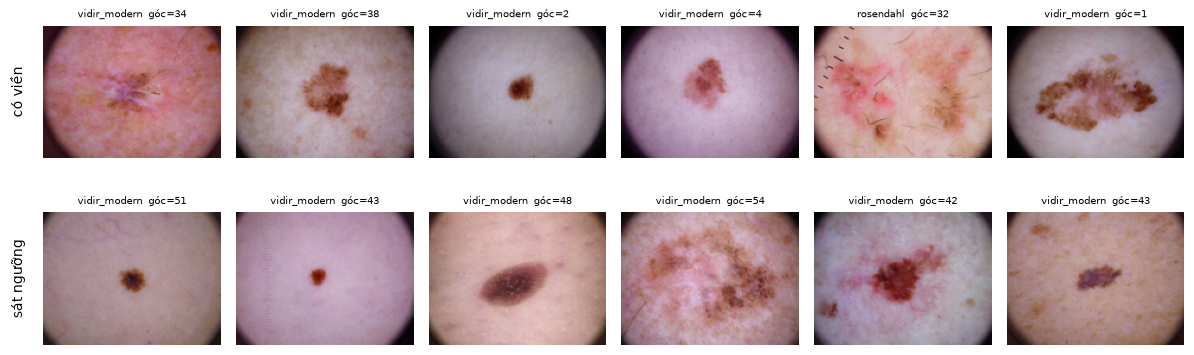

In [9]:
# kiểm bằng mắt ngưỡng viền đen: 6 ảnh bị gắn cờ, 6 ảnh sát ngưỡng phía không bị gắn cờ
co = tv[tv.vien_den].sample(min(6, tv.vien_den.sum()), random_state=0)
sat = tv[(tv.do_sang_goc >= 40) & (tv.do_sang_goc < 60)]
sat = sat.sample(min(6, len(sat)), random_state=0)
fig, ax = plt.subplots(2, 6, figsize=(12, 4.2))
for i, m in enumerate([co, sat]):
    for j in range(6):
        ax[i, j].axis("off")
        if j < len(m):
            ax[i, j].imshow(Image.open(m.duong_dan.iloc[j]).resize((150, 112)))
            ax[i, j].set_title(f"{m.nguon.iloc[j]}  góc={m.do_sang_goc.iloc[j]:.0f}", fontsize=7)
ax[0, 0].text(-0.1, 0.5, "có viền", transform=ax[0, 0].transAxes, rotation=90, va="center", ha="right")
ax[1, 0].text(-0.1, 0.5, "sát ngưỡng", transform=ax[1, 0].transAxes, rotation=90, va="center", ha="right")
plt.tight_layout(); plt.show()

## 6. Chỉ nhìn màu, có đoán được ảnh từ nguồn nào không?

Đây là phép thử quan trọng nhất của notebook. Huấn luyện một hồi quy logistic, chỉ cho nó xem mấy con
số màu ở trên, rồi bắt nó đoán nguồn. Kiểm định chéo 5 phần, chia theo tổn thương. Chỉ số là balanced
accuracy, đoán bừa được 0,25.

Có một cái bẫy: nguồn và loại bệnh dính vào nhau (vidir_molemax gần như toàn NV). Mô hình có thể đoán
nguồn **gián tiếp qua loại bệnh**: nhìn ra NV thì đoán molemax. Vì vậy chạy bốn phiên bản:

| Phiên bản | Mô hình được xem | Ý nghĩa |
|---|---|---|
| A | chỉ nhãn bệnh | đoán nguồn bằng loại bệnh thôi được bao nhiêu (mốc so) |
| B | màu vùng giữa, mọi lớp | |
| C | màu vùng giữa, **chỉ ảnh NV** | không còn đường gián tiếp qua loại bệnh |
| D | màu + độ tối góc, chỉ ảnh NV | thêm viền đen thì đoán được thêm bao nhiêu |

**C là con số cần nhìn.**

In [10]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedGroupKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import balanced_accuracy_score, confusion_matrix

def thu(Xf, d, ma_hoa=None):
    y = d.nguon.map({s: i for i, s in enumerate(NGUON)}).values
    buoc = [ma_hoa or StandardScaler(), LogisticRegression(max_iter=2000, class_weight="balanced")]
    cv = StratifiedGroupKFold(5, shuffle=True, random_state=0)
    yh = cross_val_predict(make_pipeline(*buoc), Xf, y, cv=cv, groups=d.lesion_id.values)
    return balanced_accuracy_score(y, yh), confusion_matrix(y, yh, labels=range(len(NGUON)))

MAU = COT[:6]
kq = {
    "A  chỉ nhãn bệnh":             thu(tv[["lop"]].values, tv, OneHotEncoder()),
    "B  màu giữa, mọi lớp":         thu(tv[MAU].values, tv),
    "C  màu giữa, chỉ NV":          thu(nv[MAU].values, nv),
    "D  màu + độ tối góc, chỉ NV":  thu(nv[COT].values, nv),
}
for k, (ba, _) in kq.items():
    print(f"{k:<30} balanced accuracy = {ba:.3f}   (đoán bừa 0.250)")
print("\nMa trận nhầm lẫn của C (hàng = nguồn thật, cột = nguồn đoán):")
display(pd.DataFrame(kq["C  màu giữa, chỉ NV"][1], index=NGUON, columns=NGUON))

A  chỉ nhãn bệnh               balanced accuracy = 0.415   (đoán bừa 0.250)
B  màu giữa, mọi lớp           balanced accuracy = 0.767   (đoán bừa 0.250)
C  màu giữa, chỉ NV            balanced accuracy = 0.804   (đoán bừa 0.250)
D  màu + độ tối góc, chỉ NV    balanced accuracy = 0.822   (đoán bừa 0.250)

Ma trận nhầm lẫn của C (hàng = nguồn thật, cột = nguồn đoán):


,vidir_molemax,vidir_modern,rosendahl,vienna_dias
vidir_molemax,3534,19,74,93
vidir_modern,24,1218,469,121
rosendahl,23,188,565,27
vienna_dias,10,19,7,314


## 7. Ghi file và tóm tắt

`ketqua/nguon.csv` có các cột: ảnh, tổn thương, phần (train/val), nguồn, cách xác nhận chẩn đoán, có
viền đen hay không. Bước 6 đọc file này để chia máy trạm theo nguồn thật.

Ô cuối in một bản tóm tắt ngắn. **Cậu dán đúng bản tóm tắt đó cho tớ** là đủ để viết kết luận của bước
3 và quyết định bước 5.

In [11]:
tv[["image", "lesion_id", "phan", "lop", "nguon", "dx_type", "do_sang_goc", "vien_den"]].to_csv(RA / "nguon.csv", index=False)
print(f"Đã ghi {RA / 'nguon.csv'}  ({len(tv)} dòng)\n")

print("===== TÓM TẮT NOTEBOOK 03 =====")
print("Ảnh train theo nguồn:", tr.nguon.value_counts().reindex(NGUON).to_dict())
print(bang_js[["kich_ban", "JS_tb", "JS_max"]].to_string(index=False))
print("Tỉ lệ NV theo nguồn (%):", pt["NV"].round(1).to_dict())
print("follow_up theo nguồn (%):", xn.get("follow_up", pd.Series(0, index=NGUON)).round(1).to_dict())
print("Viền đen theo nguồn (%):", (tv.groupby("nguon").vien_den.mean().reindex(NGUON) * 100).round(1).to_dict())
for k, (ba, _) in kq.items():
    print(f"Đoán nguồn — {k}: {ba:.3f}")

Đã ghi /home/deep/ham_fl/ketqua/nguon.csv  (10015 dòng)

===== TÓM TẮT NOTEBOOK 03 =====
Ảnh train theo nguồn: {'vidir_molemax': 3388, 'vidir_modern': 2904, 'rosendahl': 1926, 'vienna_dias': 365}
  kich_ban  JS_tb  JS_max
       iid  0.027   0.033
    dir1.0  0.213   0.467
    dir0.3  0.416   0.594
    dir0.1  0.534   0.757
NGUỒN THẬT  0.214   0.286
Tỉ lệ NV theo nguồn (%): {'vidir_molemax': 94.3, 'vidir_modern': 54.6, 'rosendahl': 35.3, 'vienna_dias': 78.6}
follow_up theo nguồn (%): {'vidir_molemax': 93.8, 'vidir_modern': 0.0, 'rosendahl': 0.0, 'vienna_dias': 0.0}
Viền đen theo nguồn (%): {'vidir_molemax': 0.0, 'vidir_modern': 9.6, 'rosendahl': 1.4, 'vienna_dias': 0.0}
Đoán nguồn — A  chỉ nhãn bệnh: 0.415
Đoán nguồn — B  màu giữa, mọi lớp: 0.767
Đoán nguồn — C  màu giữa, chỉ NV: 0.804
Đoán nguồn — D  màu + độ tối góc, chỉ NV: 0.822


## Kết luận bước 3  ·  *(viết sau khi có số)*

| Câu hỏi | Trả lời | Quyết định cho bước sau |
|---|---|---|
| 2. Lệch nhãn tự nhiên tương đương kịch bản Dirichlet nào? | | |
| 3. Nhãn có đáng tin như nhau? | | |
| 4. Ảnh có trông khác nhau? | | |
| 5. Đoán được nguồn khi chỉ xét NV? | | bước 5 (chuẩn hoá màu), bước 8 (FedBN) |